# Query-based detector: RT-DETR-L

This notebook covers the **query-based** checkpoint. It uses the same protocol as the Faster R-CNN notebook:

- the same data (frames sub-sampled with stride 3, ignore regions masked in train), rebuilt from the competition files in the first cell
- the same experiment subsets (2,000 train / 500 val frames, evenly spaced so every clip stays represented)
- the same number of epochs, the same augmentation (horizontal flip only) and per-step updates
- the same pycocotools evaluation, in which ignore regions are `iscrowd = 1` and so are not penalised

**Model.** RT-DETR-L (HGNetv2 backbone, COCO-pretrained) through Ultralytics. Plain DETR only reads the stride-32 map, where half of the
VisDrone objects (< 32 px at 1280) cover less than one cell. RT-DETR decodes from stride 8/16/32 with deformable attention, and its
hybrid encoder runs self-attention on S5 only, so a 1280 input stays affordable.

**Sections**

1. Setup and data
2. Training and evaluation helpers
3. Parameter study (queries, backbone learning rate, denoising, matching cost)
4. Final model on the full training set
5. Convergence against a CNN detector under the same budget
6. Small objects and dense scenes
7. NMS: why the query-based model does not need it

## 1. Data and setup

### Preprocessing (same as `01_preprocessing_eda`)

Runs on the competition data attached to this Kaggle notebook and writes a working copy to `/tmp/hw2_data` (rebuilt each session, a few minutes):

- **Frame sub-sampling** with stride 3 in train and val (neighbouring frames are near-duplicates, median box IoU 0.73 after 3 frames).
- **Ignore regions** greyed out (value 114) in **train** images only, then the pixels of every labelled box are restored. Val stays untouched,
  as the scorer sees it.
- **Annotations**: the COCO json restricted to the kept frames (ignore regions stay `iscrowd = 1`, one copy per class, for pycocotools).
  YOLO label files are linked, not copied.

Unmasked images and labels are symlinks to the read-only input, so only the masked train frames are actually written to disk.

In [1]:
import json, os
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
from PIL import Image

COMPETITION = 'multiple-object-video-detection-hw-2-ucu-ai-2026'
TRAIN_STRIDE, VAL_STRIDE = 3, 3
ROOT = Path(f'/tmp/hw2_data_s{TRAIN_STRIDE}_s{VAL_STRIDE}')


def find_competition_data():
    # Kaggle mounts competition data under /kaggle/input/<slug> (newer images: /kaggle/input/competitions/<slug>)
    for base in [Path('/kaggle/input') / COMPETITION, Path('/kaggle/input/competitions') / COMPETITION]:
        if (base / 'train' / 'annotations_coco.json').exists():
            return base
    hits = sorted(Path('/kaggle/input').glob('*/train/annotations_coco.json')) + \
           sorted(Path('/kaggle/input').glob('*/*/train/annotations_coco.json'))
    assert hits, 'Attach the competition data to the notebook: Add Input -> Competitions'
    return hits[0].parent.parent


def mask_ignore_regions(img, regions, keep_boxes, fill=114):
    # Grey out ignore regions of an HxWx3 uint8 image, but keep the pixels of labelled boxes
    h, w = img.shape[:2]

    def window(x, y, bw, bh):
        return slice(max(int(y), 0), min(int(np.ceil(y + bh)), h)), slice(max(int(x), 0), min(int(np.ceil(x + bw)), w))

    out = img.copy()
    for r in regions:
        out[window(*r)] = fill
    for b in keep_boxes:
        out[window(*b)] = img[window(*b)]
    return out


def link(src, dst):
    dst.parent.mkdir(parents=True, exist_ok=True)
    if not dst.exists():
        os.symlink(src, dst)


def prepare_split(split, stride, mask):
    d = json.load(open(SRC / split / 'annotations_coco.json'))
    keep = {im['id'] for im in d['images'] if (im['frame_id'] - 1) % stride == 0 and (SRC / split / im['file_name']).exists()}
    d['images'] = [im for im in d['images'] if im['id'] in keep]
    d['annotations'] = [a for a in d['annotations'] if a['image_id'] in keep]

    regions, boxes = {}, {}
    for a in d['annotations']:
        if a.get('iscrowd', 0):
            regions.setdefault(a['image_id'], set()).add(tuple(a['bbox']))  # stored once per class: deduplicate
        else:
            boxes.setdefault(a['image_id'], []).append(a['bbox'])

    def one(im):
        src, dst = SRC / split / im['file_name'], ROOT / split / im['file_name']
        label = Path(im['file_name'].replace('images/', 'labels/', 1)).with_suffix('.txt')
        if (SRC / split / label).exists():
            link(SRC / split / label, ROOT / split / label)
        if mask and im['id'] in regions:
            if not dst.exists():
                dst.parent.mkdir(parents=True, exist_ok=True)
                img = np.asarray(Image.open(src).convert('RGB'))
                masked = mask_ignore_regions(img, regions[im['id']], boxes.get(im['id'], ()))
                Image.fromarray(masked).save(dst, 'JPEG', quality=95)
            return 1
        link(src, dst)
        return 0

    with ThreadPoolExecutor(8) as pool:
        n_masked = sum(pool.map(one, d['images']))
    json.dump(d, open(ROOT / split / 'annotations_coco.json', 'w'))
    print(f'{split}: {len(d["images"]):,} frames kept (stride {stride}), {n_masked:,} with ignore regions masked, '
          f'{sum(not a.get("iscrowd", 0) for a in d["annotations"]):,} objects')
    return d


SRC = find_competition_data()
print('competition data:', SRC)
done = ROOT / '.done'
if done.exists():
    print('preprocessed data already in', ROOT)
else:
    (ROOT / 'train').mkdir(parents=True, exist_ok=True)
    (ROOT / 'val').mkdir(parents=True, exist_ok=True)
    train_json = prepare_split('train', TRAIN_STRIDE, mask=True)
    prepare_split('val', VAL_STRIDE, mask=False)
    cats = sorted(train_json['categories'], key=lambda c: c['id'])
    (ROOT / 'train' / 'data.yaml').write_text(json.dumps({'names': [c['name'] for c in cats]}))  # JSON is valid YAML
    done.touch()

competition data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
train: 8,090 frames kept (stride 3), 6,053 with ignore regions masked, 370,072 objects
val: 951 frames kept (stride 3), 0 with ignore regions masked, 38,206 objects


In [2]:
# Pinned to the version this notebook was written against (decoder attributes and optimizer groups are version-specific).
# Needs Internet on in the notebook settings (pip and the pretrained weights).
!pip install -q ultralytics==8.4.206 pycocotools

In [3]:
import shutil, time, math, random
from functools import partial

import pandas as pd
import yaml
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.ops import box_iou, batched_nms

from ultralytics import RTDETR, YOLO
from ultralytics.models.rtdetr.train import RTDETRTrainer
from ultralytics.models.utils.loss import RTDETRDetectionLoss

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU - turn on the GPU accelerator')

# /kaggle/working is kept as the notebook's output when you save a version
OUT = Path('/kaggle/working/rtdetr_runs')
OUT.mkdir(parents=True, exist_ok=True)

# To continue runs from an earlier version: attach that version's output as an input and point PREVIOUS_RUNS at its rtdetr_runs folder.
# Finished runs are then loaded instead of retrained, and unfinished ones resume from last.pt.
PREVIOUS_RUNS = None   # e.g. Path('/kaggle/input/<your-notebook>/rtdetr_runs')
if PREVIOUS_RUNS and Path(PREVIOUS_RUNS).exists():
    shutil.copytree(PREVIOUS_RUNS, OUT, dirs_exist_ok=True)

LISTS = Path('/tmp/lists')   # image lists and data yamls (cheap to rebuild)
LISTS.mkdir(exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: Tesla T4


**Protocol constants.** These match the Faster R-CNN notebook (epochs, subset sizes, score threshold, detections per image).
`IMGSZ = 1280` comes from the EDA: at 640 about 54% of objects would be under 16 px, at 1280 about 10%.

In [4]:
SEED = 0
EPOCHS = 6              # final model
EXP_EPOCHS = 2          # each parameter experiment
EXP_TRAIN_IMAGES = 2000 # experiments use a part of the data, so they finish in reasonable time
EXP_VAL_IMAGES = 500

IMGSZ = 1280
BATCH_SIZE = 4          # RT-DETR-L at 1280 with AMP fits a 16 GB T4; lower to 2 on CUDA out of memory
LR = 1e-4               # AdamW, the standard RT-DETR learning rate
MAX_DET = 300           # same cap as Faster R-CNN, used for every model in the comparison
SCORE_THRESH = 0.01     # low threshold is standard for mAP

names = yaml.safe_load(open(ROOT / 'train' / 'data.yaml'))['names']
names = [names[k] for k in sorted(names)] if isinstance(names, dict) else names
NUM_CLASSES = len(names)
print(NUM_CLASSES, 'classes:', names)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

8 classes: ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']


### Frames and annotations

`CocoSplit` mirrors `CocoFrames` from the Faster R-CNN notebook: same filtering, same frame order and the same evenly spaced subsets,
so `exp_val` contains exactly the frames the Faster R-CNN experiments were scored on. Ultralytics trains from YOLO label files, so each
subset is written out as a list of image paths; labels are found by replacing `/images/` with `/labels/` in each path.

In [5]:
class CocoSplit:
    def __init__(self, split, limit=None):
        self.split = split
        self.coco = COCO(str(ROOT / split / 'annotations_coco.json'))
        anns = self.coco.dataset['annotations']
        good = [a for a in anns if a['category_id'] in self.coco.cats and a['bbox'][2] > 0 and a['bbox'][3] > 0]
        for a in good:
            a.setdefault('iscrowd', 0)
            a.setdefault('area', a['bbox'][2] * a['bbox'][3])
        self.coco.dataset['annotations'] = good
        self.coco.createIndex()

        for self.folder in [ROOT / split, ROOT / split / 'images']:
            self.ids = [i for i, im in sorted(self.coco.imgs.items()) if (self.folder / im['file_name']).exists()]
            if self.ids:
                break
        assert self.ids, f'No images from the {split} json were found on disk'
        total = len(self.ids)
        if limit and limit < total:  # evenly spaced, so every clip stays represented
            self.ids = [self.ids[k] for k in np.linspace(0, total - 1, limit).astype(int)]

        cats = sorted(self.coco.cats.values(), key=lambda c: c['id'])
        if all(c['name'] in names for c in cats):
            self.cat2cls = {c['id']: names.index(c['name']) for c in cats}
        else:
            print('WARNING: json category names differ from data.yaml, matching them by order')
            self.cat2cls = {c['id']: k for k, c in enumerate(cats)}
        print(f'{split}: using {len(self.ids):,} frames ({total:,} on disk)')

    def path(self, image_id):
        return self.folder / self.coco.imgs[image_id]['file_name']

    def n_objects(self, image_id):
        return sum(1 for a in self.coco.imgToAnns[image_id] if not a['iscrowd'])

    def write_list(self, name):
        p = LISTS / f'{name}.txt'
        p.write_text(''.join(f'{self.path(i)}\n' for i in self.ids))
        return p


def check_labels(ds):
    img = str(ds.path(ds.ids[0]))
    assert '/images/' in img, f'Ultralytics needs an /images/ folder in the path: {img}'
    lbl = Path(img.replace('/images/', '/labels/')).with_suffix('.txt')
    assert lbl.exists(), f'missing YOLO label file {lbl}'


def write_data_yaml(name, train_ds, val_ds):
    p = LISTS / f'{name}.yaml'
    p.write_text(yaml.safe_dump({
        'train': str(train_ds.write_list(f'{name}_train')),
        'val': str(val_ds.write_list(f'{name}_val')),
        'nc': NUM_CLASSES,
        'names': dict(enumerate(names)),
    }))
    return p


train_ds, val_ds = CocoSplit('train'), CocoSplit('val')
exp_train, exp_val = CocoSplit('train', limit=EXP_TRAIN_IMAGES), CocoSplit('val', limit=EXP_VAL_IMAGES)
check_labels(train_ds); check_labels(val_ds)

DATA_FULL = write_data_yaml('full', train_ds, val_ds)
DATA_EXP = write_data_yaml('exp', exp_train, exp_val)

loading annotations into memory...
Done (t=1.88s)
creating index...
index created!
creating index...
index created!
train: using 8,090 frames (8,090 on disk)
loading annotations into memory...
Done (t=0.14s)
creating index...
index created!
creating index...
index created!
val: using 951 frames (951 on disk)
loading annotations into memory...
Done (t=1.72s)
creating index...
index created!
creating index...
index created!
train: using 2,000 frames (8,090 on disk)
loading annotations into memory...
Done (t=0.14s)
creating index...
index created!
creating index...
index created!
val: using 500 frames (951 on disk)


## 2. Training and evaluation helpers

### Run configuration

Each experiment is a small dict of changes to RT-DETR's defaults. Ultralytics rebuilds the model from its yaml when training starts, so
the changes are applied in a callback after that rebuild, on both the trained model and its EMA copy (the EMA weights are the ones that get
validated and saved). The callback also runs after a resume.

| key | what it changes | default |
|---|---|---|
| `nq` | number of object queries (= encoder tokens kept by query selection) | 300 |
| `nd` | denoising query budget, split into groups of noisy copies of the GT boxes | 100 |
| `backbone_lr_mult` | backbone learning rate as a fraction of `LR` | 1.0 |
| `cost_gain` | weights of the Hungarian matching cost (class, L1, GIoU) | 2 / 5 / 2 |

In [6]:
def unwrap(m):
    return getattr(m, 'module', m)


def set_decoder(model, nq=None, nd=None):
    head = unwrap(model).model[-1]  # RTDETRDecoder
    if nq is not None:
        head.num_queries = nq
    if nd is not None:
        head.num_denoising = nd


def matcher_criterion(model, cost_gain):
    crit = RTDETRDetectionLoss(nc=model.nc, use_vfl=True)
    crit.matcher.cost_gain = dict(cost_gain)
    return crit


def make_callback(cfg):
    def apply(trainer):
        targets = [trainer.model] + ([trainer.ema.ema] if getattr(trainer, 'ema', None) else [])
        for m in targets:
            set_decoder(m, cfg.get('nq'), cfg.get('nd'))
        if 'cost_gain' in cfg:
            m = unwrap(trainer.model)
            m.init_criterion = partial(matcher_criterion, m, cfg['cost_gain'])  # survives the re-init on resume
            m.criterion = None
    return apply


class BackboneLRTrainer(RTDETRTrainer):
    # Split every optimizer group into a backbone part and the rest, the backbone part at a lower learning rate.
    # The groups keep their 'param_group' tag, so Ultralytics' warmup and weight decay still treat them correctly.
    backbone_lr_mult = 1.0

    def build_optimizer(self, model, *args, **kwargs):
        opt = super().build_optimizer(model, *args, **kwargs)
        if self.backbone_lr_mult == 1.0:
            return opt
        m = unwrap(model)
        n_backbone = len(m.yaml['backbone'])
        backbone = {id(p) for layer in m.model[:n_backbone] for p in layer.parameters()}
        extra = []
        for g in opt.param_groups:
            moved = [p for p in g['params'] if id(p) in backbone]
            g['params'] = [p for p in g['params'] if id(p) not in backbone]
            if moved:
                extra.append({**{k: v for k, v in g.items() if k != 'params'}, 'params': moved,
                              'lr': g['lr'] * self.backbone_lr_mult})
        for g in extra:
            opt.add_param_group(g)
        print(f'backbone: {sum(len(g["params"]) for g in extra)} tensors at lr x{self.backbone_lr_mult}')
        return opt


def trainer_for(cfg):
    mult = cfg.get('backbone_lr_mult', 1.0)
    return type('Trainer', (BackboneLRTrainer,), {'backbone_lr_mult': mult})

### Training

Same augmentation as the Faster R-CNN baseline (**horizontal flip only**), so differences between the detectors come from the architecture.
Mosaic, scale jitter and colour augmentation are left for the final pipeline notebook. `nbs = BATCH_SIZE` turns off Ultralytics' gradient
accumulation to a nominal batch of 64: with 2,000 images that would leave about 30 optimizer steps per epoch.
`device=0` keeps training on one GPU: on Kaggle's 2x T4, Ultralytics would otherwise start DDP in a subprocess, which
drops the custom trainer and callbacks. `deterministic=False` is needed because `grid_sample` (deformable attention) has no deterministic backward on CUDA.

In [7]:
TRAIN_ARGS = dict(
    imgsz=IMGSZ, batch=BATCH_SIZE, nbs=BATCH_SIZE, workers=4, seed=SEED, device=0 if DEVICE == 'cuda' else 'cpu', deterministic=False, amp=True,
    optimizer='AdamW', lr0=LR, lrf=0.1, weight_decay=1e-4, warmup_epochs=1, cos_lr=True,
    mosaic=0.0, mixup=0.0, copy_paste=0.0, close_mosaic=0, scale=0.0, translate=0.0,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, fliplr=0.5, erasing=0.0,
    max_det=MAX_DET, plots=False, exist_ok=True, project=str(OUT), verbose=False,
)


def completed_epochs(run_dir):
    csv = run_dir / 'results.csv'
    return len(pd.read_csv(csv)) if csv.exists() else 0


def train_run(name, epochs, data, cfg=None, weights='rtdetr-l.pt', family=RTDETR, **overrides):
    # Trains or resumes. A finished run is loaded from its best.pt. Delete OUT/<name> to retrain from scratch.
    cfg = cfg or {}
    run_dir = OUT / name
    best, last = run_dir / 'weights' / 'best.pt', run_dir / 'weights' / 'last.pt'
    done = completed_epochs(run_dir)
    is_detr = family is RTDETR

    if done >= epochs and best.exists():
        print(f'{name}: finished ({done}/{epochs} epochs), loading best.pt')
    else:
        resume = last.exists() and 0 < done < epochs
        model = family(str(last) if resume else weights)
        if is_detr:
            model.add_callback('on_pretrain_routine_end', make_callback(cfg))
        extra = {'trainer': trainer_for(cfg)} if is_detr else {}
        print(f'{name}: {"resuming at epoch " + str(done + 1) if resume else "training"}, {epochs} epochs, cfg {cfg or "defaults"}')
        if resume:  # the run's own arguments are read back from last.pt
            model.train(resume=True, **extra)
        else:
            model.train(**dict(TRAIN_ARGS, data=str(data), epochs=epochs, name=name, **overrides), **extra)

    model = family(str(best))
    if is_detr:
        set_decoder(model.model, cfg.get('nq'), cfg.get('nd'))  # also stored in the checkpoint; set again to be safe
    return model

### Prediction and COCO evaluation

`predict` returns the same structure as the Faster R-CNN notebook (`image_id -> (classes, scores, xyxy boxes)`), so `coco_eval` is the
same function, extended with AP for medium and large objects and the recall at `MAX_DET` (AR). A subset of frames can be scored on its own
with `img_ids`, which is used for the density analysis.

Note: Ultralytics' RT-DETR predictor resizes every frame to a square `IMGSZ x IMGSZ` (it stretches instead of letterboxing), and boxes are
mapped back to the original frame. The training dataloader does the same, so train and inference agree.

In [8]:
@torch.no_grad()
def predict(model, ds, max_det=MAX_DET, batch=8, **kw):
    results = {}
    for k in tqdm(range(0, len(ds.ids), batch), desc='predict'):
        ids = ds.ids[k:k + batch]
        out = model.predict([str(ds.path(i)) for i in ids], imgsz=IMGSZ, conf=SCORE_THRESH, max_det=max_det,
                            half=DEVICE == 'cuda', verbose=False, **kw)
        for image_id, r in zip(ids, out):  # results come back in input order
            b = r.boxes
            results[image_id] = (b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy(), b.xyxy.cpu().numpy())
    return results


def coco_eval(results, ds, img_ids=None, max_det=MAX_DET):
    cls2cat = {k: cat for cat, k in ds.cat2cls.items()}
    detections = [
        {'image_id': image_id, 'category_id': cls2cat[int(c)], 'score': float(s),
         'bbox': [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]}
        for image_id, (cls, scores, boxes) in results.items()
        for c, s, (x1, y1, x2, y2) in zip(cls, scores, boxes)
    ]
    assert detections, 'The model produced no detections'
    ev = COCOeval(ds.coco, ds.coco.loadRes(detections), 'bbox')
    ev.params.imgIds = list(img_ids if img_ids is not None else ds.ids)
    ev.params.maxDets = [1, 10, max_det]
    ev.evaluate()
    ev.accumulate()

    precision = ev.eval['precision']  # [IoU threshold, recall, class, area range, max detections]
    recall = ev.eval['recall']        # [IoU threshold, class, area range, max detections]
    def mean(p):
        return float(p[p > -1].mean()) if (p > -1).any() else float('nan')
    metrics = {'mAP': mean(precision[:, :, :, 0, -1]),
               'AP50': mean(precision[0, :, :, 0, -1]),
               'AP_small': mean(precision[:, :, :, 1, -1]),
               'AP_medium': mean(precision[:, :, :, 2, -1]),
               'AP_large': mean(precision[:, :, :, 3, -1]),
               f'AR@{max_det}': mean(recall[:, :, 0, -1])}
    per_class = {names[ds.cat2cls[cat]]: mean(precision[:, :, k, 0, -1]) for k, cat in enumerate(ev.params.catIds)}
    return metrics, per_class


def quiet_eval(*a, **k):
    # pycocotools prints a summary per call; keep the notebook output short
    import contextlib, io
    with contextlib.redirect_stdout(io.StringIO()):
        return coco_eval(*a, **k)


@torch.no_grad()
def inference_ms(model, ds, n=100):
    # Milliseconds per image, one image at a time: resize + forward + postprocess, without file loading (images are preloaded)
    images = [np.asarray(Image.open(ds.path(i)).convert('RGB'))[:, :, ::-1] for i in ds.ids[:n]]  # BGR like cv2
    model.predict(images[0], imgsz=IMGSZ, half=DEVICE == 'cuda', verbose=False)  # warm-up
    total = 0.0
    for im in images:
        r = model.predict(im, imgsz=IMGSZ, conf=SCORE_THRESH, max_det=MAX_DET, half=DEVICE == 'cuda', verbose=False)[0]
        total += sum(r.speed.values())
    return total / len(images)

## 3. Parameter study

Every run starts from the COCO-pretrained `rtdetr-l.pt`, trains for `EXP_EPOCHS` on the 2,000-frame subset and is scored on the same 500
validation frames as the Faster R-CNN experiments. Each experiment changes one thing against the baseline.

| run | change | why, from the data |
|---|---|---|
| `baseline` | RT-DETR defaults | reference |
| `queries_500` | 300 -> 500 queries | ~46 objects per frame, 95th percentile 118, up to 180. Query selection keeps the top-k encoder tokens, and with 300 the densest frames can run out of good candidates |
| `backbone_lr_0.1` | backbone at 0.1 x LR | the official RT-DETR recipe: the pretrained backbone should move slower than the randomly initialised decoder |
| `dn_300` | denoising budget 100 -> 300 | (loss) Ultralytics splits the budget into groups of one noisy copy per GT box. A batch with 100+ objects gets a single group at 100, and frames above the budget are only partly denoised |
| `match_giou_4` | matching cost GIoU weight 2 -> 4 | (loss) for tiny boxes the L1 term in normalised coordinates is very small, so the matcher is driven mostly by the class score. More GIoU weight favours queries whose boxes actually overlap the object |

In [9]:
EXPERIMENTS = {
    'baseline':        {},
    'queries_500':     {'nq': 500},
    'backbone_lr_0.1': {'backbone_lr_mult': 0.1},
    'dn_300':          {'nd': 300},
    'match_giou_4':    {'cost_gain': {'class': 2, 'bbox': 5, 'giou': 4}},
}

rows = []
for name, cfg in EXPERIMENTS.items():
    model = train_run(f'exp_{name}', EXP_EPOCHS, DATA_EXP, cfg)
    results = predict(model, exp_val)
    metrics, _ = quiet_eval(results, exp_val)
    rows.append({'run': name, **metrics, 'ms_per_image': inference_ms(model, exp_val)})
    del model
    torch.cuda.empty_cache()

experiments = pd.DataFrame(rows).set_index('run').round(4)
experiments.to_csv(OUT / 'experiments.csv')
best_run = experiments['mAP'].idxmax()
print('Best run:', best_run)
experiments

exp_baseline: training, 2 epochs, cfg defaults
New https://pypi.org/project/ultralytics/8.4.207 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.206 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/lists/exp.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


        2/2      10.8G     0.6443      0.735    0.08305        125       1280: 100% ━━━━━━━━━━━━ 500/500 1.2it/s 6:45
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 1.7it/s 37.2s
                   all        500      20112      0.202      0.391      0.183     0.0999

2 epochs completed in 0.248 hours.
Optimizer stripped from /kaggle/working/rtdetr_runs/exp_baseline/weights/last.pt, 66.5MB
Optimizer stripped from /kaggle/working/rtdetr_runs/exp_baseline/weights/best.pt, 66.5MB

Validating /kaggle/working/rtdetr_runs/exp_baseline/weights/best.pt...
Ultralytics 8.4.206 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 105.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 1.6it/s 40.0s
                   all        500      20112      0.203       0.39      0.182  

predict:   0%|          | 0/63 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

predict:   0%|          | 0/63 [00:00<?, ?it/s]

... (4 outputs left out)

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

predict:   0%|          | 0/63 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,mAP,AP50,AP_small,AP_medium,AP_large,AR@300,ms_per_image
run,,,,,,,
baseline,0.1057,0.1940,0.0433,0.0863,0.2334,0.3357,93.9228
queries_500,0.1437,0.2629,0.0594,0.1327,0.2761,0.3116,93.4670
backbone_lr_0.1,0.1000,0.1842,0.0366,0.0894,0.2212,0.3279,93.4092
dn_300,0.0927,0.1728,0.0437,0.0838,0.1908,0.2950,93.0269
match_giou_4,0.0788,0.1421,0.0294,0.0713,0.1719,0.2861,93.5798


**Reading the table.** For `queries_500` look at AR first: more queries can only help recall, and with the score cap at `MAX_DET = 300`
the gain can only come from better query selection in dense frames. For the loss changes compare `AP_small` with the overall mAP.
Two epochs on 2,000 frames is a short budget for a DETR, so small differences (under about 0.005 mAP) are within run-to-run noise.

*Write your observations here.*

## 4. Final model

The best configuration from the study, trained on all training frames for `EPOCHS` epochs and scored on the full validation set.

In [10]:
FINAL_CFG = EXPERIMENTS[best_run]
detr = train_run('final', EPOCHS, DATA_FULL, FINAL_CFG)

detr_val = predict(detr, val_ds)
metrics, per_class = quiet_eval(detr_val, val_ds)
ms = inference_ms(detr, val_ds)

report = pd.Series({**metrics, 'ms_per_image': ms, 'FPS': 1000 / ms}).round(4)
report.to_csv(OUT / 'final_metrics.csv')
print('Parameters from the study:', FINAL_CFG or 'defaults')
print(report, '\n')
print(pd.Series(per_class, name='AP per class').sort_values().round(4))

final: training, 6 epochs, cfg {'nq': 500}
New https://pypi.org/project/ultralytics/8.4.207 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.206 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/lists/full.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=tr

predict:   0%|          | 0/119 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

## 5. Convergence against a CNN detector under the same budget

The CNN reference is an anchor-free YOLO trained with the **same data, input size, epochs, batch size and augmentation**. It keeps its usual
optimizer (SGD, lr 0.01), because YOLO with the DETR learning rate would not be a fair baseline. If the anchor-free notebook already has a
YOLO run trained under this protocol, point `CNN_RESULTS` at its folder to reuse it instead of training a new one.

Both curves use Ultralytics' validation mAP50-95 after each epoch. It ignores the ignore regions, so its absolute values are lower than the
pycocotools numbers above, but the two curves are comparable with each other. The x axis is shown both in epochs and in training minutes,
since a DETR epoch costs more time than a YOLO epoch.

cnn_yolo11l: training, 6 epochs, cfg defaults
New https://pypi.org/project/ultralytics/8.4.207 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.206 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/lists/full.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=

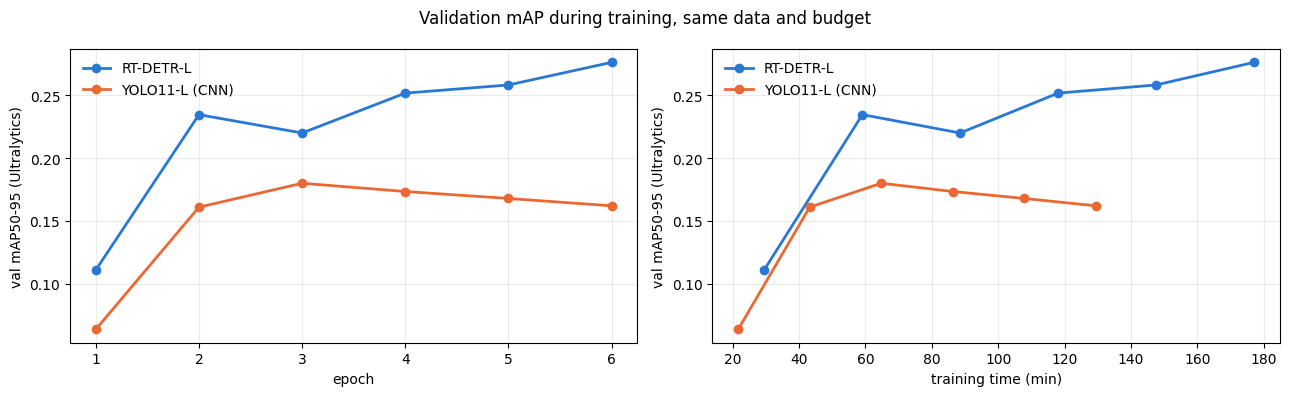

,metrics/mAP50(B),metrics/mAP50-95(B),still improving
RT-DETR-L,0.51220,0.27632,True
YOLO11-L (CNN),0.32881,0.16208,False


In [11]:
CNN_WEIGHTS = 'yolo11l.pt'   # YOLO11 still uses NMS, which the comparison in section 7 needs
CNN_RESULTS = None           # e.g. Path('/kaggle/input/<yolo-notebook>/yolo_runs/final') to reuse an existing run

if CNN_RESULTS is None:
    cnn = train_run('cnn_yolo11l', EPOCHS, DATA_FULL, weights=CNN_WEIGHTS, family=YOLO,
                    optimizer='SGD', lr0=0.01, lrf=0.01, warmup_epochs=1)
    CNN_RESULTS = OUT / 'cnn_yolo11l'
else:
    cnn = YOLO(str(Path(CNN_RESULTS) / 'weights' / 'best.pt'))

curves = {'RT-DETR-L': pd.read_csv(OUT / 'final' / 'results.csv'), 'YOLO11-L (CNN)': pd.read_csv(Path(CNN_RESULTS) / 'results.csv')}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (label, df), color in zip(curves.items(), ['#2a78d6', '#eb6834']):
    df.columns = df.columns.str.strip()
    ax[0].plot(df['epoch'], df['metrics/mAP50-95(B)'], 'o-', color=color, lw=2, label=label)
    ax[1].plot(df['time'] / 60, df['metrics/mAP50-95(B)'], 'o-', color=color, lw=2, label=label)
ax[0].set_xlabel('epoch'); ax[1].set_xlabel('training time (min)')
for a in ax:
    a.set_ylabel('val mAP50-95 (Ultralytics)'); a.legend(frameon=False); a.grid(alpha=0.25)
fig.suptitle('Validation mAP during training, same data and budget')
plt.tight_layout(); plt.savefig(OUT / 'convergence.png', dpi=150); plt.show()

last = pd.DataFrame({k: v.iloc[-1][['metrics/mAP50(B)', 'metrics/mAP50-95(B)']] for k, v in curves.items()}).T
last['still improving'] = [v['metrics/mAP50-95(B)'].iloc[-1] > v['metrics/mAP50-95(B)'].iloc[-2] + 0.002 for v in curves.values()]
last

**Convergence.** If the RT-DETR curve is still rising at the last epoch, the model has not converged within the budget, and the report should
say so. Things to look at: does mAP50 rise faster than mAP50-95 (the queries find the objects but localise them loosely), and how far behind
the YOLO curve RT-DETR starts (the decoder and the class head start from scratch for these 8 classes, YOLO's dense head adapts faster).

*Write your observations here.*

## 6. Small objects and dense scenes

Both final models are scored with the same pycocotools evaluation, broken down by object size (COCO areas) and by scene density.
The density bins follow the EDA: the median frame has ~37 objects in val and the 95th percentile ~103.

In [12]:
cnn_val = predict(cnn, val_ds)
models = {'RT-DETR-L': detr_val, 'YOLO11-L (CNN)': cnn_val}

frcnn_csv = Path('/kaggle/input/frcnn-results/final_metrics.csv')  # upload the Faster R-CNN final_metrics.csv as a dataset
by_size = pd.DataFrame({k: quiet_eval(v, val_ds)[0] for k, v in models.items()}).T
if frcnn_csv.exists():  # tuned two-stage model from the Faster R-CNN notebook, when available
    by_size.loc['Faster R-CNN'] = pd.read_csv(frcnn_csv, index_col=0).iloc[:, 0]
by_size.round(4)

predict:   0%|          | 0/119 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,mAP,AP50,AP_small,AP_medium,AP_large,AR@300
RT-DETR-L,0.2821,0.5246,0.1444,0.2908,0.3944,0.4335
YOLO11-L (CNN),0.1706,0.3418,0.1119,0.1832,0.2642,0.2783


In [13]:
counts = pd.Series({i: val_ds.n_objects(i) for i in val_ds.ids})
bins = {'sparse (<= 25)': counts[counts <= 25].index,
        'medium (26-60)': counts[(counts > 25) & (counts <= 60)].index,
        'dense (> 60)': counts[counts > 60].index}

rows = []
for model_name, res in models.items():
    for bin_name, ids in bins.items():
        m, _ = quiet_eval(res, val_ds, img_ids=ids)
        rows.append({'model': model_name, 'scene': bin_name, 'frames': len(ids), **m})
density = pd.DataFrame(rows).set_index(['scene', 'model']).sort_index().round(4)
density.to_csv(OUT / 'density.csv')
density[['frames', 'mAP', 'AP50', 'AP_small', f'AR@{MAX_DET}']]

frames     mAP    AP50  AP_small  AR@300
scene          model                                                   
dense (> 60)   RT-DETR-L          156  0.3107  0.6316    0.1071  0.4292
               YOLO11-L (CNN)     156  0.2531  0.5013    0.0760  0.3847
medium (26-60) RT-DETR-L          458  0.2970  0.5241    0.1626  0.4480
               YOLO11-L (CNN)     458  0.1796  0.3413    0.1321  0.2918
sparse (<= 25) RT-DETR-L          337  0.1802  0.2974    0.0389  0.3153
               YOLO11-L (CNN)     337  0.0485  0.0951    0.0289  0.0823

*Write your observations here: does the gap between RT-DETR and the CNN grow with density, and is it mostly on small objects?*

### What the errors look like

The densest validation frame: ground truth on the left, confident predictions (score > 0.3) of each model on the right.

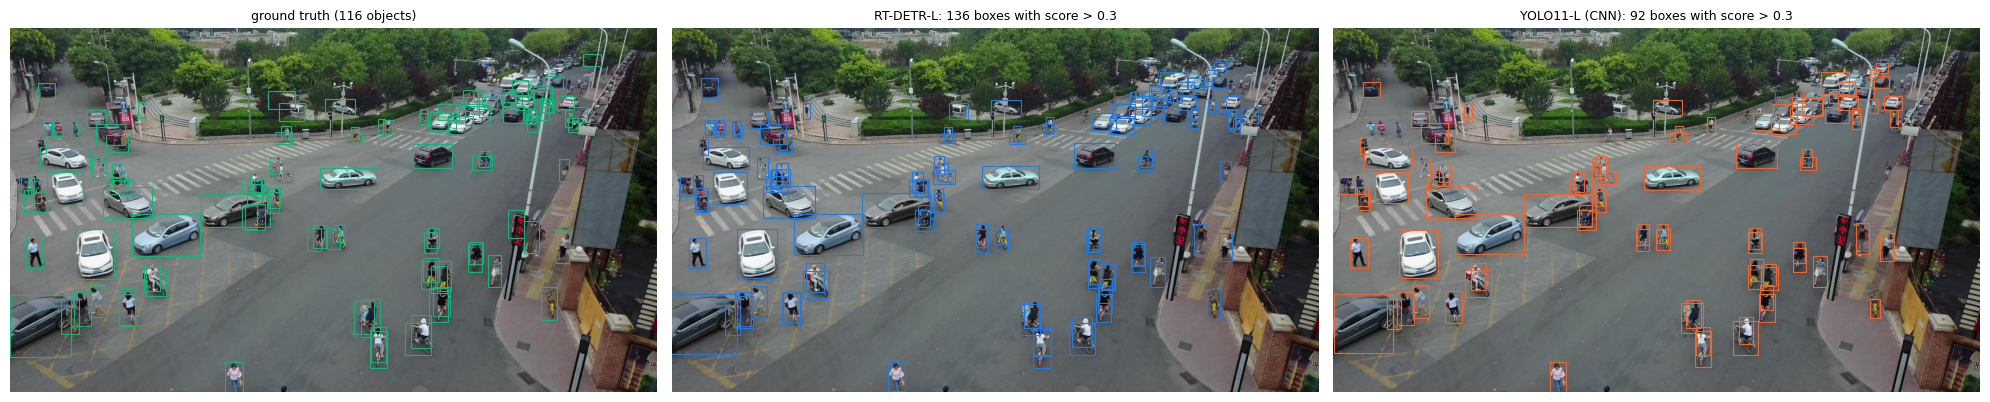

In [14]:
def draw(ax, image_id, boxes, color, title):
    ax.imshow(Image.open(val_ds.path(image_id)))
    for x1, y1, x2, y2 in boxes:
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, lw=0.8))
    ax.set_title(title, fontsize=9); ax.axis('off')

dense_id = counts.idxmax()
gt = [[x, y, x + w, y + h] for a in val_ds.coco.imgToAnns[dense_id] if not a['iscrowd'] for x, y, w, h in [a['bbox']]]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
draw(axes[0], dense_id, gt, '#1baf7a', f'ground truth ({len(gt)} objects)')
for ax, (name, res), color in zip(axes[1:], models.items(), ['#2a78d6', '#eb6834']):
    _, scores, boxes = res[dense_id]
    keep = boxes[scores > 0.3]
    draw(ax, dense_id, keep, color, f'{name}: {len(keep)} boxes with score > 0.3')
plt.tight_layout(); plt.show()

## 7. NMS: why the query-based model does not need it

During training each object is matched to exactly one query, so a second query on the same object is trained towards "no object". The decoder's
self-attention lets queries see each other and avoid duplicates. Two checks:

1. **Duplicate rate**: the share of confident predictions (score > 0.25) that overlap a higher-scoring prediction of the same class with IoU > 0.7.
   RT-DETR raw output is compared with YOLO with its NMS effectively turned off (`iou=1.0` only removes exact duplicates).
2. **NMS on top of RT-DETR**: if the model already outputs one box per object, adding NMS should change mAP very little.

In [15]:
def duplicate_rate(results, score=0.25, iou=0.7):
    dup = total = 0
    for cls, scores, boxes in results.values():
        keep = scores > score
        cls, scores, boxes = cls[keep], scores[keep], torch.as_tensor(boxes[keep])
        if len(scores) == 0:
            continue
        order = np.argsort(-scores)
        cls, boxes = cls[order], boxes[order]
        ious = box_iou(boxes, boxes).numpy()
        same = cls[:, None] == cls[None, :]
        higher = np.tril(np.ones_like(ious, dtype=bool), -1)  # j scored higher than i
        dup += int(((ious > iou) & same & higher).any(axis=1).sum())
        total += len(scores)
    return dup / max(total, 1)


def add_nms(results, iou=0.7):
    out = {}
    for k, (cls, scores, boxes) in results.items():
        keep = batched_nms(torch.as_tensor(boxes), torch.as_tensor(scores), torch.as_tensor(cls), iou).numpy()
        out[k] = (cls[keep], scores[keep], boxes[keep])
    return out


cnn_no_nms = predict(cnn, val_ds, iou=1.0)
nms_table = pd.DataFrame({
    'RT-DETR, raw (no NMS)':   {'duplicate rate': duplicate_rate(detr_val), 'mAP': quiet_eval(detr_val, val_ds)[0]['mAP']},
    'RT-DETR + NMS 0.7':       {'duplicate rate': duplicate_rate(add_nms(detr_val)), 'mAP': quiet_eval(add_nms(detr_val), val_ds)[0]['mAP']},
    'YOLO, NMS off (iou=1.0)': {'duplicate rate': duplicate_rate(cnn_no_nms), 'mAP': quiet_eval(cnn_no_nms, val_ds)[0]['mAP']},
    'YOLO, default NMS':       {'duplicate rate': duplicate_rate(cnn_val), 'mAP': quiet_eval(cnn_val, val_ds)[0]['mAP']},
}).T.round(4)
nms_table.to_csv(OUT / 'nms.csv')
nms_table

predict:   0%|          | 0/119 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,duplicate rate,mAP
"RT-DETR, raw (no NMS)",0.1237,0.2821
RT-DETR + NMS 0.7,0.0000,0.2846
"YOLO, NMS off (iou=1.0)",0.8467,0.0464
"YOLO, default NMS",0.0011,0.1706


*Write your observations here.* Expected pattern: RT-DETR's raw duplicate rate is already low and NMS barely moves its mAP, while YOLO
without NMS has many duplicates and loses mAP. In very dense scenes NMS can also remove true neighbours, which the query-based model avoids.

## Summary

*Fill in after the runs: the selected configuration, final val metrics, whether the model converged within the budget, and how it compares
with the two-stage and one-stage detectors on small objects and dense scenes.*